# Understand LunarLander: observations, engines, and a tiny DDPG agent

Start here before reading [analysis.ipynb](analysis.ipynb). That notebook interprets saved research runs; this one starts with what the agent sees and does, then **trains a new, small agent** and shows its flight.

By the end you should be able to read all eight observation values, translate the two action values into engine power, follow one transition, and connect a flight to its learning curve. No saved pilot/study data is needed.

**Run All performs 20,000 training transitions on CPU.** The actor and critic each have two hidden layers of 32 units. This is a learning demonstration, not a promise of solving LunarLander. Every run writes to a fresh directory under `outputs/environment-walkthrough/`; it does not modify the study data.

From this repository root, start the locked environment:

```bash
uv sync --locked
uv run --locked jupyter lab notebooks/environment_walkthrough.ipynb
```

Choose the kernel belonging to `.venv` (the setup in [PORTABILITY.md](../docs/PORTABILITY.md) also registers a named kernel). The saved plots can be read without running cells; flight controls require a trusted notebook or the exported HTML opened in a browser.

In [1]:
from pathlib import Path
import copy
import importlib.metadata
import inspect
import json
import sys
import time
from datetime import datetime, timezone
from uuid import uuid4

import gymnasium as gym
import numpy as np
import torch
from torch import nn
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, Markdown, display
from gymnasium.envs.box2d import lunar_lander as lander_source

from lunarlander_rl.paths import project_root

PROJECT = project_root()
from lunarlander_rl.experiment import Actor, Critic, bellman_target

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})
VERSIONS = {name: importlib.metadata.version(name)
            for name in ("gymnasium", "torch", "numpy", "Box2D")}
print("Versions:", VERSIONS)
print("Kernel:", sys.executable)

ENV_SETTINGS = dict(continuous=True, gravity=-10.0, enable_wind=False)
HORIZON = 1000
FPS = lander_source.FPS
NAMES = ["x", "y", "vx", "vy", "angle", "angular_velocity", "leg_0_contact", "leg_1_contact"]

def make_env(render=False):
    return gym.make("LunarLander-v3", **ENV_SETTINGS, max_episode_steps=HORIZON,
                    render_mode="rgb_array" if render else None)

probe_env = make_env(render=True)
try:
    first_obs, info = probe_env.reset(seed=42)
    first_frame = probe_env.render()
    print("Observation space:", probe_env.observation_space)
    print("Action space:", probe_env.action_space)
    print("reset info:", info)
finally:
    probe_env.close()

Versions: {'gymnasium': '1.3.0', 'torch': '2.14.0', 'numpy': '2.4.6', 'Box2D': '2.3.10'}
Kernel: /Users/kat/Projects/master_ue/RL/miniproject1-DDPG/.venv/bin/python3
Observation space: Box([ -2.5        -2.5       -10.        -10.         -6.2831855 -10.
  -0.         -0.       ], [ 2.5        2.5       10.        10.         6.2831855 10.
  1.         1.       ], (8,), float32)
Action space: Box(-1.0, 1.0, (2,), float32)
reset info: {}


## 1. What is the environment?

A simulated craft falls under gravity toward the flat landing area between two flags. A random initial push and random terrain make each episode different. The main engine brakes the fall; side engines change lateral motion and rotation. Fuel is unlimited, but using engines costs reward. Wind is disabled, matching the project's experiments.

The agent receives **a vector of eight numbers**, not the rendered image. We often call it the *state* `s`, but Gymnasium calls it an *observation*: the simulator also holds terrain, leg joints and other internal information. You cannot restore the simulator just by assigning an observation vector.

A **step** advances physics by `1/50` second. An **episode** runs from reset until a physical ending or the 1,000-step limit (20 simulated seconds). Training time on your computer is different from simulated time.

The API is:

```python
obs, info = env.reset(seed=42)
next_obs, reward, terminated, truncated, info = env.step(action)
```

`info` is supplementary metadata (empty here). A **transition** is `(obs, action, reward, next_obs, terminated, truncated)`. An episode is a sequence of transitions; a trajectory is that sequence viewed as a path through states.

Reference: [Gymnasium LunarLander documentation](https://gymnasium.farama.org/environments/box2d/lunar_lander/). The equations and boundary details below are checked against the installed implementation, whose file is printed later.

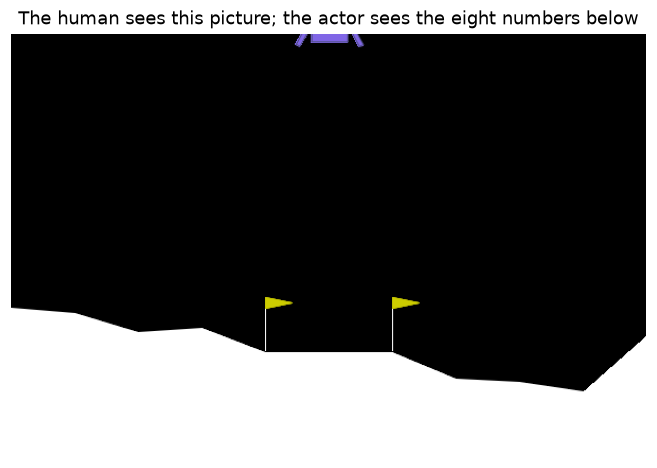

| index | name | reset value |
|---:|---|---:|
| 0 | `x` | +0.00230 |
| 1 | `y` | +1.41813 |
| 2 | `vx` | +0.23265 |
| 3 | `vy` | +0.32047 |
| 4 | `angle` | -0.00265 |
| 5 | `angular_velocity` | -0.05270 |
| 6 | `leg_0_contact` | +0.00000 |
| 7 | `leg_1_contact` | +0.00000 |

In [2]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.imshow(first_frame)
ax.set_title("The human sees this picture; the actor sees the eight numbers below")
ax.axis("off")
plt.show()
display(Markdown("| index | name | reset value |\n|---:|---|---:|\n" +
                 "\n".join(f"| {i} | `{name}` | {value:+.5f} |"
                           for i, (name, value) in enumerate(zip(NAMES, first_obs)))))

## 2. Read every observation component

Indices start at zero. Position and velocity are scaled by the environment; **they are not all metres or metres/second, and they are not all constrained to `[-1, 1]`.** We feed these existing observations directly into the network without additional normalization.

| Index | Name | Meaning and sign | Example |
|---:|---|---|---|
| 0 | `x` | Horizontal displacement from the landing area's center; positive is right, negative left. `x = ±1` is the horizontal viewport boundary. | `x = +0.2`: right of center. |
| 1 | `y` | Vertical displacement from the nominal hull-center landing height; positive is above it. The reference includes the leg-length offset above the pad. | `y = +0.5`: still high above the target. |
| 2 | `vx` | Scaled horizontal velocity; positive moves right. | `vx = -0.1`: moving left, even if `x` is positive. |
| 3 | `vy` | Scaled vertical velocity; positive moves up, negative falls. | `vy = -0.3`: descending. |
| 4 | `angle` | Hull rotation in **radians** from upright. Positive is counterclockwise (top tilted left), negative clockwise. | `+0.1` rad ≈ `+5.7°`. |
| 5 | `angular_velocity` | Scaled rotation rate; positive turns counterclockwise. This value is **0.4 × radians/second** with default FPS. | `+0.2` corresponds to `+0.5` rad/s. |
| 6 | `leg_0_contact` | `1.0` if the first leg in the simulator touches ground, otherwise `0.0`. In this implementation it is on the right when upright. | Contact can turn on and off. |
| 7 | `leg_1_contact` | Same for the second leg, on the left when upright. | Both `1` does not by itself end the episode. |

**Position is not velocity.** A craft can be right of the target (`x > 0`) while moving toward it (`vx < 0`). Likewise, a nearly upright craft can be rotating rapidly and about to tip. This is why the actor needs more than `x,y`.

For the default viewport and scale, let `X,Y` be hull position and `Vx,Vy` its velocity in Box2D world units, and `Y_pad` be pad height:

$$
\begin{aligned}
x &= \frac{X-10}{10}, & y &= \frac{Y-(Y_{\mathrm{pad}}+0.6)}{20/3}, \\
v_x &= \frac{V_x}{5}, & v_y &= \frac{V_y}{7.5}, \\
\theta &= \text{hull angle}, & \omega &= 0.4\,\Omega.
\end{aligned}
$$

Thus `10*x` is horizontal world displacement and `(20/3)*y` is vertical world displacement from the nominal landing hull center. These are simulator units. `y=0` is a useful target reference, not an exact contact test: ground geometry and leg motion matter. The final two components supply contact information.

The `Box` printed above declares allowed ranges. Those bounds are not the meaning or units of each variable.

## 3. Read every action component

DDPG needs continuous actions. Here `action = [main, lateral]`, two floats in `[-1,1]`. They are **commands**, not accelerations or desired coordinates. Both components can activate at once.

| Index | Command | Actual behavior in the installed environment |
|---:|---|---|
| 0 | `main` | If `main <= 0`, engine off. If `main > 0`, power fraction is `(main + 1)/2`: just over 50% up to 100%. |
| 1 | `lateral` | If `abs(lateral) <= 0.5`, both side engines off. Below `-0.5`, fire the left orientation engine; above `+0.5`, fire the right. Power fraction is `abs(lateral)`. |

At **exactly zero** the main engine is off. At **exactly ±0.5** the side engines are off. The documentation's prose rounds these boundary cases; the installed `step()` uses strict `>` conditions.

For an upright craft, a negative lateral command pushes left and tends to turn the craft counterclockwise; a positive command pushes right and tends to turn it clockwise. These are the environment's names for orientation actions, rather than a description of which physical side emits exhaust. As the craft tilts, the force direction rotates with it. A positive lateral command names an engine, not a target position. A main thrust can also move the craft sideways when tilted.

Examples: `[-1,0]` switches everything off; `[1,0]` fires main at full power; `[0.2,-0.8]` fires main at 60% and the left side engine at 80%. `[0,0]` is also entirely off.

Below, note the **dead zones** and sudden onset of at least half power. Smooth actor outputs do not imply smooth engine activation.

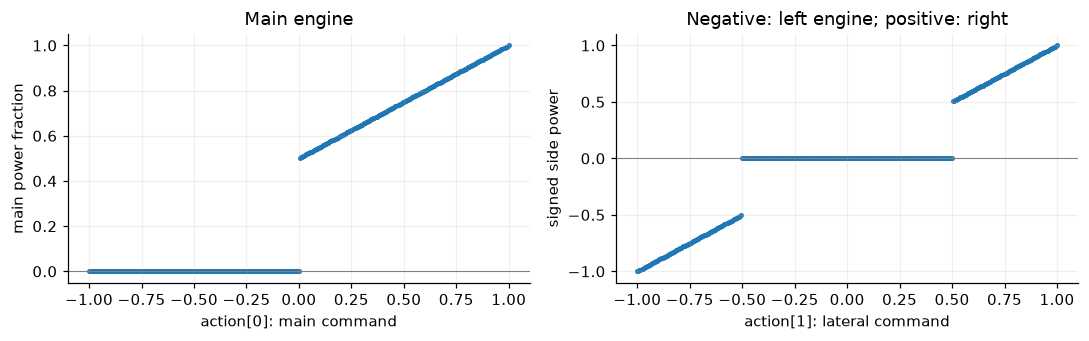

Commands:
 [[ 0.   0. ]
 [ 1.   0.5]
 [ 0.2 -0.8]
 [-1.   1. ]]
Decoded main / signed side power: (array([0. , 1. , 0.6, 0. ]), array([ 0. ,  0. , -0.8,  1. ]))


In [3]:
def engine_power(actions):
    """Exact command-to-power map from LunarLander.step; side sign names the engine."""
    a = np.clip(np.asarray(actions), -1, 1)
    main = np.where(a[..., 0] > 0, (a[..., 0] + 1) / 2, 0)
    side = np.where(np.abs(a[..., 1]) > 0.5, np.abs(a[..., 1]), 0)
    return main, np.sign(a[..., 1]) * side

commands = np.unique(np.r_[np.linspace(-1, 1, 401), -0.5, 0, 0.5])
m, _ = engine_power(np.column_stack([commands, np.zeros_like(commands)]))
_, side = engine_power(np.column_stack([np.zeros_like(commands), commands]))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
axes[0].scatter(commands, m, s=5)
axes[0].set(xlabel="action[0]: main command", ylabel="main power fraction", title="Main engine")
axes[1].scatter(commands, side, s=5)
axes[1].set(xlabel="action[1]: lateral command", ylabel="signed side power", title="Negative: left engine; positive: right")
for ax in axes:
    ax.axhline(0, color="grey", lw=0.7)
    ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

# These edge cases matter when interpreting a plotted action.
edge_actions = np.array([[0, 0], [1, 0.5], [0.2, -0.8], [-1, 1]])
print("Commands:\n", edge_actions)
print("Decoded main / signed side power:", engine_power(edge_actions))

### Check lateral direction with a controlled comparison

For the same nearly upright reset, compare one negative or positive side command with an all-off command. The table subtracts the all-off successor: negative lateral pushes `vx` lower and rotation rate higher; positive does the reverse. These short comparisons explain engine direction, not how to land. The leg positions also verify the observation indices directly against the installed simulator.

In [4]:
successors = {}
for lateral in (-1.0, 0.0, 1.0):
    env = make_env()
    try:
        obs, _ = env.reset(seed=42)
        if lateral == 0:
            print("Leg indices and horizontal positions:",
                  [(i, round(leg.position.x, 3)) for i, leg in enumerate(env.unwrapped.legs)])
            print("Hull horizontal position:", round(env.unwrapped.lander.position.x, 3))
        successors[lateral] = env.step(np.array([-1, lateral], dtype=np.float32))[0]
    finally:
        env.close()
rows = "\n".join(f"| {cmd:+.0f} | {state[2]-successors[0.0][2]:+.5f} | "
                 f"{state[5]-successors[0.0][5]:+.5f} |" for cmd, state in successors.items())
display(Markdown("| lateral command | vx change relative to off | rotation-rate change relative to off |\n"
                 "|---:|---:|---:|\n" + rows))

Leg indices and horizontal positions: [(0, 10.893), (1, 9.151)]
Hull horizontal position: 10.023


| lateral command | vx change relative to off | rotation-rate change relative to off |
|---:|---:|---:|
| -1 | -0.01201 | +0.04817 |
| +0 | +0.00000 | +0.00000 |
| +1 | +0.00771 | -0.03092 |

### One real transition, before any learning

Reset to the same seed and apply `[0.2,-0.8]` once. The action is chosen from `s_0`, then physics returns `s_1` and `r_1`. In general the reward reflects changes in several quantities; a single action is not guaranteed to move directly toward the target.

In [5]:
env = make_env()
try:
    s0, _ = env.reset(seed=42)
    a0 = np.array([0.2, -0.8], dtype=np.float32)
    s1, r1, terminated, truncated, info = env.step(a0)
finally:
    env.close()
rows = "\n".join(f"| `{name}` | {before:+.5f} | {after:+.5f} | {after-before:+.5f} |"
                 for name, before, after in zip(NAMES, s0, s1))
display(Markdown("| component | before: s0 | after: s1 | change |\n|---|---:|---:|---:|\n" + rows))
print(f"a0 = {a0}, r1 = {r1:+.4f}, terminated = {terminated}, truncated = {truncated}")

| component | before: s0 | after: s1 | change |
|---|---:|---:|---:|
| `x` | +0.00230 | +0.00442 | +0.00213 |
| `y` | +1.41813 | +1.42543 | +0.00730 |
| `vx` | +0.23265 | +0.21374 | -0.01891 |
| `vy` | +0.32047 | +0.32434 | +0.00387 |
| `angle` | -0.00265 | -0.00379 | -0.00114 |
| `angular_velocity` | -0.05270 | -0.02276 | +0.02994 |
| `leg_0_contact` | +0.00000 | +0.00000 | +0.00000 |
| `leg_1_contact` | +0.00000 | +0.00000 | +0.00000 |

a0 = [ 0.2 -0.8], r1 = -0.2900, terminated = False, truncated = False


## 4. What earns reward, and what ends a flight?

The simulator computes a shaping score from the current observation:

$$
F(s)=-100\sqrt{x^2+y^2}-100\sqrt{v_x^2+v_y^2}-100|\theta|+10c_L+10c_R.
$$

On an ordinary transition:

$$
r_{t+1}=F(s_{t+1})-F(s_t)-0.30\,p_{\mathrm{main}}-0.03\,p_{\mathrm{side}}.
$$

Moving closer, slowing down, becoming upright and gaining leg contact tend to help. Losing contact reverses the contact bonus. Remaining in contact does **not** earn +10 every frame. Engine use is penalized even though fuel is unlimited.

A crash (hull touching ground) or horizontal escape (`abs(x) >= 1`) **replaces** that step's reward with `-100`. When the hull comes to rest and Box2D puts it to sleep, the terminal reward becomes `+100`. The sleep check is last in the implementation. A total episode return around 200 is the conventional solution reference, but one flight cannot establish reliable performance.

Two flags end collection:

- **`terminated=True`**: a physical ending, including crash, escape or rest. There is no future reward after that terminal transition.
- **`truncated=True`**: the external time limit stopped collection. The dynamics could have continued. A hovering policy can reach this limit without landing.

The training target zeros future value only for `terminated`. We still reset on either flag. This matches the existing project trainer.

**Return** here means the undiscounted sum of rewards in an episode. The critic learns a different quantity: a discounted expected return with `gamma=0.99`. A critic loss is not a landing score.

In [6]:
def shaping(s):
    return (-100 * np.linalg.norm(s[:2]) - 100 * np.linalg.norm(s[2:4])
            - 100 * abs(s[4]) + 10 * s[6] + 10 * s[7])

main_power, signed_side = engine_power(a0)
reconstructed_reward = shaping(s1) - shaping(s0) - 0.30 * main_power - 0.03 * abs(signed_side)
print(f"Observed reward: {r1:+.6f}; reconstructed ordinary-step reward: {reconstructed_reward:+.6f}")
assert not terminated and np.isclose(r1, reconstructed_reward, atol=2e-4)
print("Installed environment source:", inspect.getfile(lander_source))
print("Source for the exact action boundary rules:")
step_source = inspect.getsource(lander_source.LunarLander.step)
for line in step_source.splitlines():
    if "action[0] >" in line or "np.abs(action[1]) >" in line:
        print(line.strip())

Observed reward: -0.289997; reconstructed ordinary-step reward: -0.289999
Installed environment source: /Users/kat/Projects/master_ue/RL/miniproject1-DDPG/.venv/lib/python3.11/site-packages/gymnasium/envs/box2d/lunar_lander.py
Source for the exact action boundary rules:
if (self.continuous and action[0] > 0.0) or (
if (self.continuous and np.abs(action[1]) > 0.5) or (


## 5. What does this tiny DDPG agent learn?

The **actor** maps 8 observation values to 2 commands: `8 → 32 → 32 → 2`, with ReLU hidden layers and `tanh` bounded outputs. The **critic** takes the 8 observations plus 2 commands and produces one number: `10 → 32 → 32 → 1`. We reuse the `Actor` and `Critic` classes from [experiment.py](../src/lunarlander_rl/experiment.py) with smaller hidden layers and no LayerNorm.

The actor is deterministic during evaluation. During training, we first collect 1,000 random transitions, then add Gaussian noise to actor commands so it explores. A **replay buffer** stores earlier transitions; learning uses randomly sampled batches rather than only the newest experience. This is *off-policy* learning.

For each batch, DDPG performs three operations:

1. Fit the critic to `y = r + gamma * (1 - terminated) * Q_target(s_next, actor_target(s_next))` using mean squared error.
2. Adjust the actor to increase the critic's value: minimize `-mean(Q(s, actor(s)))`. Freeze the critic's weights during this operation, while keeping gradients through its action input.
3. Move both target networks slowly toward the updated networks: `target ← (1 - tau) * target + tau * online`. These slowly changing copies stabilize the target.

The buffer stores the actual noisy action taken, while the next action in the target is recomputed by the target actor. The critic is a learned estimate, so the actor can be misled by inaccurate values.

The visible loop below is a small teaching implementation of these updates. It is separate from the multi-run research pipeline. DDPG uses one critic and updates its actor every round; the project's TD3 experiments add two critics, target smoothing and delayed actor updates.

Reference: [original DDPG paper](https://arxiv.org/abs/1509.02971).

In [7]:
# Change TRAIN_STEPS here for a longer demonstration; Run All starts a fresh run.
SEED = 7
TRAIN_STEPS = 20_000
WARMUP = 1_000
BATCH_SIZE = 64
CAPACITY = 30_000
EVAL_INTERVAL = 5_000
EVAL_SEEDS = (10_001, 10_002, 10_003)
GAMMA, TAU = 0.99, 0.005
EXPLORATION_STD = 0.15
LEARNING_RATE = 3e-4
assert TRAIN_STEPS >= WARMUP >= BATCH_SIZE and CAPACITY >= BATCH_SIZE

torch.set_num_threads(1)
torch.manual_seed(SEED)
rng = np.random.default_rng(SEED)
train_env = make_env()
actor = Actor(8, (32, 32), train_env.action_space.low, train_env.action_space.high)
critic = Critic(8, 2, (32, 32), layer_norm=False)
initial_actor = copy.deepcopy(actor).eval()
target_actor = copy.deepcopy(actor).requires_grad_(False)
target_critic = copy.deepcopy(critic).requires_grad_(False)
actor_optimizer = torch.optim.Adam(actor.parameters(), lr=LEARNING_RATE)
critic_optimizer = torch.optim.Adam(critic.parameters(), lr=LEARNING_RATE)
train_env.close()

print(actor)
print(critic)
print("Trainable parameters:", {"actor": sum(p.numel() for p in actor.parameters()),
                                "critic": sum(p.numel() for p in critic.parameters())})

# Each index stores one transition; a circular pointer replaces the oldest data.
replay = {"obs": np.zeros((CAPACITY, 8), np.float32),
          "action": np.zeros((CAPACITY, 2), np.float32),
          "reward": np.zeros(CAPACITY, np.float32),
          "next_obs": np.zeros((CAPACITY, 8), np.float32),
          "terminated": np.zeros(CAPACITY, bool)}

Actor(
  (model): Sequential(
    (0): Linear(in_features=8, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=2, bias=True)
  )
)
Critic(
  (model): Sequential(
    (0): Linear(in_features=10, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=1, bias=True)
  )
)
Trainable parameters: {'actor': 1410, 'critic': 1441}


### Collect a trajectory with correct time alignment

For a trajectory with `T` actions we save `T+1` observations: `s_0,...,s_T`. Row `t` of `actions` is chosen from `observations[t]`; `rewards[t]` is the reward returned after applying it, and `observations[t+1]` is the resulting observation. The final observation has no next action.

`render_mode='rgb_array'` creates frames without opening a game window. The playback records one image per observation. Evaluation uses no exploration noise. The named evaluation seeds are separate from the training seed.

In [8]:
def actor_policy(model):
    def policy(obs, env):
        with torch.inference_mode():
            return model(torch.as_tensor(obs, dtype=torch.float32).unsqueeze(0))[0].numpy()
    return policy

def rollout(policy, seed, render=False):
    env = make_env(render=render)
    observations, actions, rewards, frames = [], [], [], []
    try:
        obs, _ = env.reset(seed=int(seed))
        observations.append(obs.copy())
        if render:
            frames.append(env.render().copy())
        terminated = truncated = False
        while not (terminated or truncated):
            action = np.asarray(policy(obs, env), dtype=np.float32)
            assert env.action_space.contains(action)
            obs, reward, terminated, truncated, _ = env.step(action)
            actions.append(action.copy())
            rewards.append(float(reward))
            observations.append(obs.copy())
            if render:
                frames.append(env.render().copy())
        # Diagnostic outcome from simulator flags, not a reward threshold.
        base = env.unwrapped
        if terminated:
            outcome = ("at rest" if not base.lander.awake else
                       "hull contact / crash" if base.game_over else "horizontal escape")
        else:
            outcome = "time limit"
    finally:
        env.close()
    return dict(observations=np.asarray(observations), actions=np.asarray(actions),
                rewards=np.asarray(rewards), frames=frames, seed=int(seed),
                terminated=bool(terminated), truncated=bool(truncated), outcome=outcome)

def evaluate(model):
    return np.array([rollout(actor_policy(model), seed)["rewards"].sum() for seed in EVAL_SEEDS])

# Repeated checks use the same three seeds to make the change easy to follow.
evaluations = [{"step": 0, "returns": evaluate(actor)}]
print("Untrained actor returns:", evaluations[0]["returns"].round(1))

Untrained actor returns: [   8.7 -212.7 -122.8]


In [9]:
# Training cell: one environment transition, then one critic and actor update.
train_env = make_env()
obs, _ = train_env.reset(seed=SEED)
episode_return, episode_length = 0.0, 0
training_episodes, losses = [], []
started = time.perf_counter()
try:
    for step in range(1, TRAIN_STEPS + 1):
        if step <= WARMUP:
            action = rng.uniform(-1, 1, size=2).astype(np.float32)
        else:
            command = actor_policy(actor)(obs, train_env)
            action = np.clip(command + rng.normal(0, EXPLORATION_STD, 2), -1, 1).astype(np.float32)
        next_obs, reward, terminated, truncated, _ = train_env.step(action)
        slot = (step - 1) % CAPACITY
        for key, value in zip(replay, (obs, action, reward, next_obs, terminated)):
            replay[key][slot] = value
        episode_return += reward
        episode_length += 1
        obs = next_obs
        if terminated or truncated:
            training_episodes.append(dict(step=step, episode_return=float(episode_return),
                                          length=episode_length, terminated=bool(terminated),
                                          truncated=bool(truncated)))
            obs, _ = train_env.reset()
            episode_return, episode_length = 0.0, 0

        if step >= WARMUP:
            indices = rng.choice(min(step, CAPACITY), BATCH_SIZE, replace=False)
            batch = {key: torch.from_numpy(values[indices]) for key, values in replay.items()}
            with torch.no_grad():
                next_q = target_critic(batch["next_obs"], target_actor(batch["next_obs"]))
                y = bellman_target(batch["reward"], batch["terminated"], next_q, GAMMA)
            critic_loss = nn.functional.mse_loss(critic(batch["obs"], batch["action"]), y)
            critic_optimizer.zero_grad(set_to_none=True)
            critic_loss.backward()
            critic_optimizer.step()

            critic.requires_grad_(False)
            actor_loss = -critic(batch["obs"], actor(batch["obs"])).mean()
            actor_optimizer.zero_grad(set_to_none=True)
            actor_loss.backward()
            actor_optimizer.step()
            critic.requires_grad_(True)
            with torch.no_grad():
                for online, target in ((actor, target_actor), (critic, target_critic)):
                    for param, target_param in zip(online.parameters(), target.parameters()):
                        target_param.lerp_(param, TAU)
            if step % 100 == 0:
                losses.append(dict(step=step, critic=float(critic_loss.detach()),
                                   actor=float(actor_loss.detach())))

        if step % EVAL_INTERVAL == 0 or step == TRAIN_STEPS:
            returns = evaluate(actor)
            evaluations.append(dict(step=step, returns=returns))
            print(f"step {step:>6,} | evaluation returns {returns.round(1)} | "
                  f"elapsed {time.perf_counter()-started:.1f}s", flush=True)
finally:
    train_env.close()
actor.eval()
elapsed = time.perf_counter() - started
assert all(torch.isfinite(p).all() for model in (actor, critic) for p in model.parameters())
print(f"Finished {TRAIN_STEPS:,} transitions in {elapsed:.1f}s; {len(training_episodes)} complete training episodes.")

step  5,000 | evaluation returns [ -23.4  -27.3 -127.1] | elapsed 3.2s


step 10,000 | evaluation returns [-36.4   4.4 -91.6] | elapsed 7.1s


step 15,000 | evaluation returns [ -32.4   -3.3 -112.3] | elapsed 11.1s


step 20,000 | evaluation returns [-211.9   18.  -182.2] | elapsed 15.8s


Finished 20,000 transitions in 15.8s; 68 complete training episodes.


## 6. Did the behavior change?

The left plot shows complete **training episodes**, which include random warm-up and exploration noise. The right plot shows deterministic evaluations of the actor at each checkpoint. Each thin line follows one fixed evaluation seed; the thick line is their mean. They are three starting situations for one trained network, not three independent training runs and not a confidence interval.

Read the final checkpoint even if an earlier checkpoint scored better. This tutorial does not select the best checkpoint or best-looking flight. A short run can improve, stagnate or deteriorate. The 200-point reference is a guide, not evidence that this demonstration solved the task.

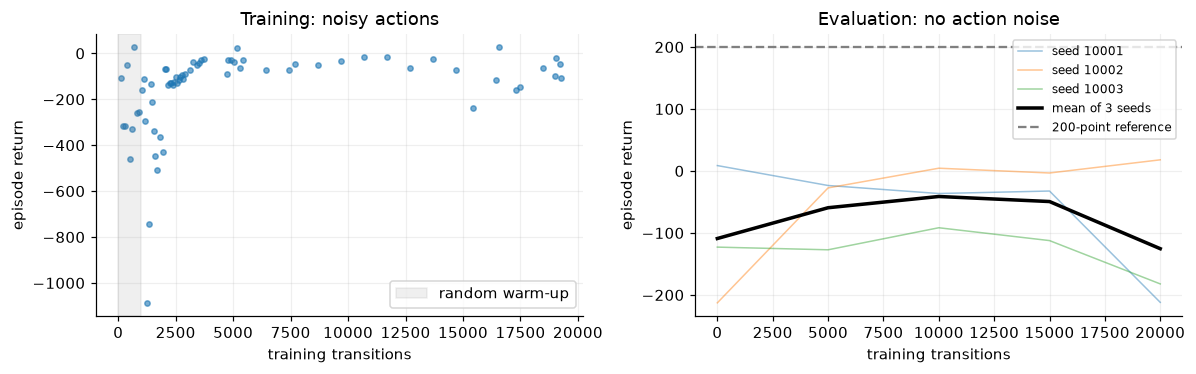

**Read this run:** the mean evaluation return changed from **-108.9** before training to **-125.4** at the final checkpoint. The final actor improved on **1 of 3** fixed starting seeds. Check the intermediate points too: early improvement can disappear. Weight updates alone do not establish a successful landing policy.

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].scatter([e["step"] for e in training_episodes],
                [e["episode_return"] for e in training_episodes], s=12, alpha=0.6)
axes[0].axvspan(0, WARMUP, alpha=0.12, color="grey", label="random warm-up")
axes[0].set(title="Training: noisy actions", ylabel="episode return", xlabel="training transitions")
axes[0].legend()
eval_steps = [e["step"] for e in evaluations]
eval_returns = np.stack([e["returns"] for e in evaluations])
for i, seed in enumerate(EVAL_SEEDS):
    axes[1].plot(eval_steps, eval_returns[:, i], alpha=0.45, lw=1, label=f"seed {seed}")
axes[1].plot(eval_steps, eval_returns.mean(axis=1), color="black", lw=2.3, label="mean of 3 seeds")
axes[1].axhline(200, color="grey", linestyle="--", label="200-point reference")
axes[1].set(title="Evaluation: no action noise", ylabel="episode return", xlabel="training transitions")
axes[1].legend(fontsize=8)
for ax in axes:
    ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

initial_mean = eval_returns[0].mean()
final_mean = eval_returns[-1].mean()
improved_starts = int(np.sum(eval_returns[-1] > eval_returns[0]))
display(Markdown(
    f"**Read this run:** the mean evaluation return changed from **{initial_mean:+.1f}** "
    f"before training to **{final_mean:+.1f}** at the final checkpoint. "
    f"The final actor improved on **{improved_starts} of {len(EVAL_SEEDS)}** fixed starting seeds. "
    "Check the intermediate points too: early improvement can disappear. "
    "Weight updates alone do not establish a successful landing policy."))

### Compare three flights from the same initial seed

We show the **first evaluation seed by construction**, not the most successful one. Compare the untrained network, the final trained network, and Gymnasium's hand-written heuristic controller. The heuristic is a reference for what a controlled descent can look like; it is not a neural network, receives no training here, and never supplies training data to DDPG.

All three flights below use the same rendered environment settings. Rendering adds decorative particles; use these rendered rollouts for the table and playback together rather than expecting bit-for-bit identity with the non-rendered learning-curve evaluations.

In [11]:
FLIGHT_SEED = EVAL_SEEDS[0]
flights = {
    "Untrained actor": rollout(actor_policy(initial_actor), FLIGHT_SEED, render=True),
    "Tiny DDPG (final)": rollout(actor_policy(actor), FLIGHT_SEED, render=True),
    "Heuristic reference": rollout(lambda obs, env: lander_source.heuristic(env, obs), FLIGHT_SEED, render=True),
}
rows = "\n".join(f"| {name} | {len(f['actions'])} | {f['rewards'].sum():+.1f} | "
                 f"{f['outcome']} | {f['terminated']} | {f['truncated']} |"
                 for name, f in flights.items())
display(Markdown("| controller | steps | total return | ending | terminated | truncated |\n"
                 "|---|---:|---:|---|---|---|\n" + rows))
for flight in flights.values():
    T = len(flight["actions"])
    assert flight["observations"].shape == (T + 1, 8)
    assert len(flight["frames"]) == T + 1 and flight["rewards"].shape == (T,)
    assert np.isfinite(flight["observations"]).all()
    assert np.isin(flight["observations"][:, 6:], [0, 1]).all()

| controller | steps | total return | ending | terminated | truncated |
|---|---:|---:|---|---|---|
| Untrained actor | 85 | +8.7 | hull contact / crash | True | False |
| Tiny DDPG (final) | 190 | -211.9 | hull contact / crash | True | False |
| Heuristic reference | 214 | +295.8 | at rest | True | False |

## 7. Watch the trajectory and read its numbers

Press play or scrub the animation slider. The three flights share simulated time; a finished flight holds its last frame. Under each view, `s_t` describes the displayed frame and `a_t` is the command about to be applied. The displayed reward is `r_(t+1)`, returned by that upcoming transition. At the final frame there is no next action or reward.

The **cumulative reward so far** includes only transitions already completed. Notice how engine commands, velocity, angle and contact relate to visible motion. Physics responds over time; an engine command is not an immediate change in position. Frames are shown every 8 steps (0.16 simulated seconds) to keep the notebook compact.

In [12]:
STRIDE = 8
max_T = max(len(f["actions"]) for f in flights.values())
frame_steps = np.unique(np.r_[np.arange(0, max_T + 1, STRIDE), max_T])
fig, axes = plt.subplots(1, 3, figsize=(12, 5.3))
images, captions = [], []
for ax, (name, flight) in zip(axes, flights.items()):
    images.append(ax.imshow(flight["frames"][0]))
    captions.append(ax.text(0, -0.07, "", transform=ax.transAxes, va="top",
                            fontfamily="monospace", fontsize=8))
    ax.set_title(name)
    ax.axis("off")
fig.subplots_adjust(left=0.02, right=0.98, top=0.86, bottom=0.27, wspace=0.08)
clock_label = fig.suptitle("")

def update_animation(index):
    t = int(frame_steps[index])
    clock_label.set_text(f"Same initial seed {FLIGHT_SEED} • simulated time {t/FPS:.2f} s")
    for image, caption, flight in zip(images, captions, flights.values()):
        k = min(t, len(flight["actions"]))
        s = flight["observations"][k]
        image.set_data(flight["frames"][k])
        text = (f"t={k}, return so far={flight['rewards'][:k].sum():+.1f}\n"
                f"x,y   = {s[0]:+.2f}, {s[1]:+.2f}\n"
                f"vx,vy = {s[2]:+.2f}, {s[3]:+.2f}\n"
                f"angle,omega = {s[4]:+.2f}, {s[5]:+.2f}\n"
                f"contacts [6],[7] = {s[6]:.0f}, {s[7]:.0f}\n")
        if k < len(flight["actions"]):
            a = flight["actions"][k]
            text += f"next a = [{a[0]:+.2f}, {a[1]:+.2f}]\nnext reward = {flight['rewards'][k]:+.2f}"
        else:
            text += f"END: {flight['outcome']}"
        caption.set_text(text)
    return images + captions + [clock_label]

animation = FuncAnimation(fig, update_animation, frames=len(frame_steps),
                          interval=1000*STRIDE/FPS, blit=False, repeat=False)
playback_html = animation.to_jshtml(default_mode="once", embed_frames=True)
plt.close(fig)
display(HTML(playback_html))

### The same paths as an `x,y` plot

This plot uses converted world displacements so equal axis lengths represent equal world distances. The dotted `y=0` line is the nominal **hull-center target height**, not the terrain outline. The landing pad spans approximately `x_world=-2` to `+2`. Start/end markers reveal whether the craft approached the pad or left the viewport. The heuristic and DDPG curves may have very different durations.

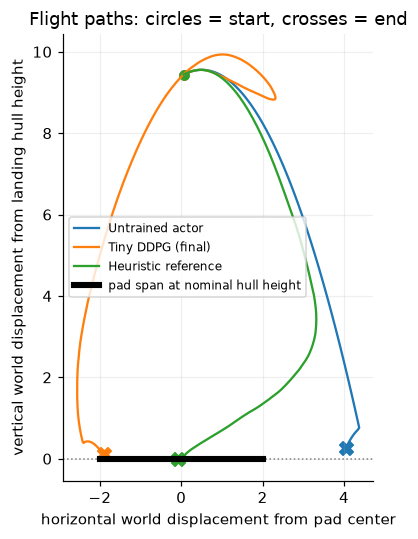

In [13]:
fig, ax = plt.subplots(figsize=(8, 5))
for name, f in flights.items():
    positions = f["observations"][:, :2] * np.array([10, 20/3])
    line, = ax.plot(*positions.T, label=name)
    ax.scatter(*positions[0], color=line.get_color(), marker="o", s=35)
    ax.scatter(*positions[-1], color=line.get_color(), marker="X", s=80)
ax.axhline(0, color="grey", linestyle=":", lw=1)
ax.plot([-2, 2], [0, 0], color="black", lw=4, label="pad span at nominal hull height")
ax.set(xlabel="horizontal world displacement from pad center",
       ylabel="vertical world displacement from landing hull height",
       title="Flight paths: circles = start, crosses = end", aspect="equal")
ax.legend(fontsize=8)
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## 8. Inspect all eight states, both commands, and reward over time

These plots show the **final tiny DDPG flight**, even if it failed. Observation curves include the final state. Action and reward curves have one fewer sample and are indexed by the state from which the action was taken.

The action panel contains the network's two command values. The next panel decodes the corresponding actual engine power. A side command within `[-0.5,0.5]` can change without ever firing an engine. Contacts are binary and shown as steps. The right-hand reward axis shows total reward accumulated so far.

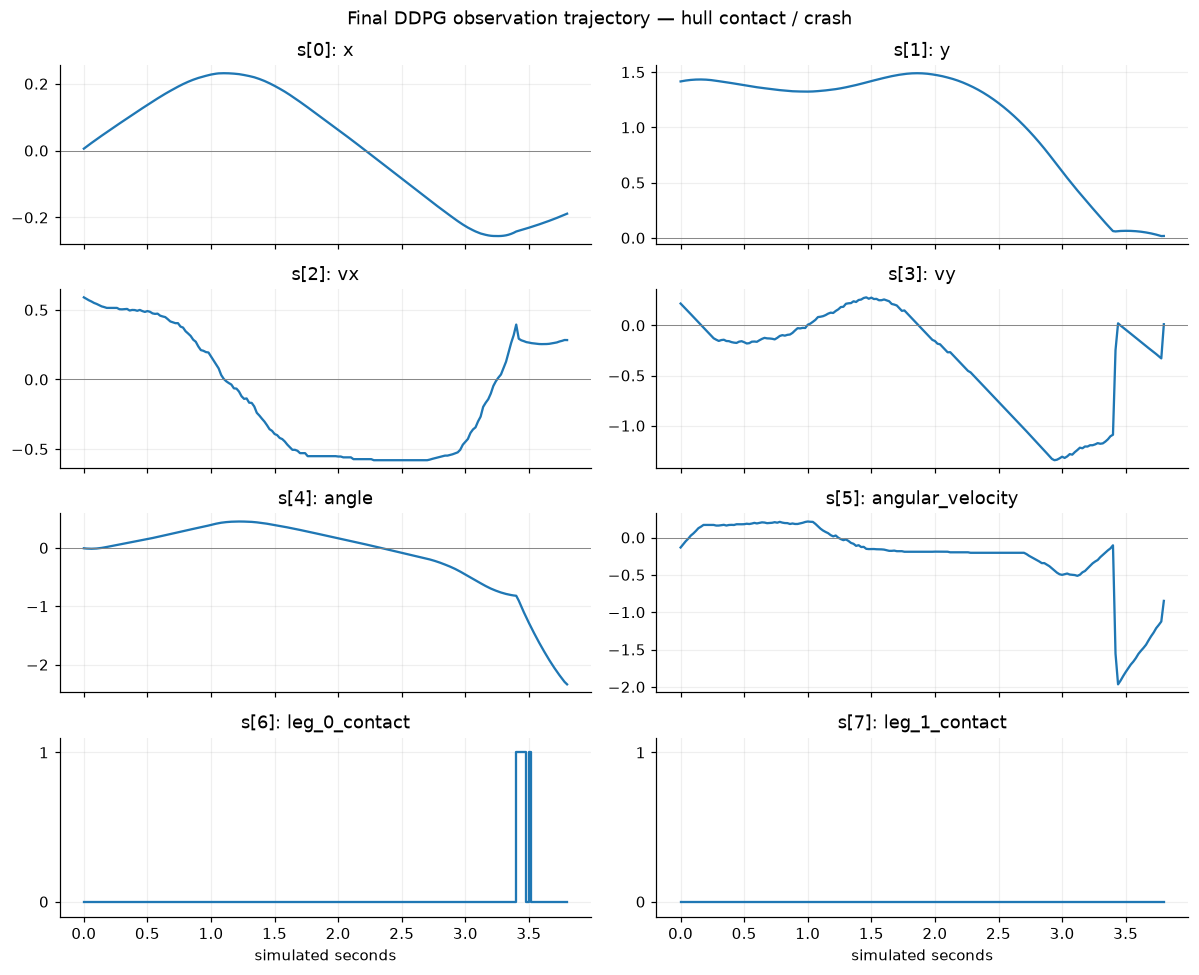

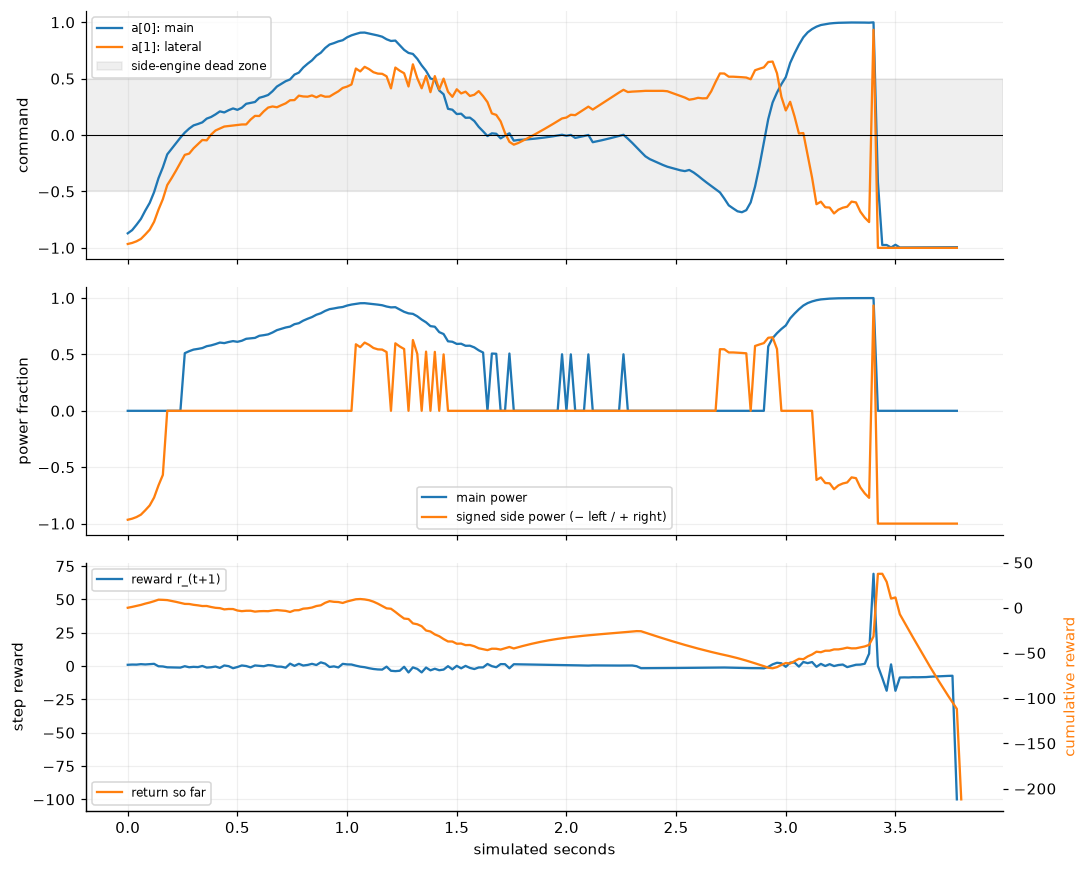

In [14]:
flight = flights["Tiny DDPG (final)"]
s = flight["observations"]
a = flight["actions"]
r = flight["rewards"]
state_time = np.arange(len(s)) / FPS
action_time = np.arange(len(a)) / FPS
fig, axes = plt.subplots(4, 2, figsize=(11, 9), sharex=True)
for i, ax in enumerate(axes.flat):
    if i >= 6:
        ax.step(state_time, s[:, i], where="post")
        ax.set_yticks([0, 1])
        ax.set_ylim(-0.1, 1.1)
    else:
        ax.plot(state_time, s[:, i])
        ax.axhline(0, color="grey", lw=0.6)
    ax.set_title(f"s[{i}]: {NAMES[i]}")
    ax.grid(alpha=0.2)
for ax in axes[-1]:
    ax.set_xlabel("simulated seconds")
fig.suptitle(f"Final DDPG observation trajectory — {flight['outcome']}")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
axes[0].plot(action_time, a[:, 0], label="a[0]: main")
axes[0].plot(action_time, a[:, 1], label="a[1]: lateral")
axes[0].axhspan(-0.5, 0.5, color="grey", alpha=0.12, label="side-engine dead zone")
axes[0].axhline(0, color="black", lw=0.7)
axes[0].set(ylabel="command", ylim=(-1.1, 1.1))
main_power, side_power = engine_power(a)
axes[1].plot(action_time, main_power, label="main power")
axes[1].plot(action_time, side_power, label="signed side power (− left / + right)")
axes[1].set(ylabel="power fraction", ylim=(-1.1, 1.1))
axes[2].plot(action_time, r, color="tab:blue", label="reward r_(t+1)")
axes[2].set(ylabel="step reward", xlabel="simulated seconds")
return_axis = axes[2].twinx()
return_axis.plot(state_time, np.r_[0, np.cumsum(r)], color="tab:orange", label="return so far")
return_axis.set_ylabel("cumulative reward", color="tab:orange")
for ax in axes:
    ax.legend(loc="best", fontsize=8)
    ax.grid(alpha=0.2)
return_axis.legend(loc="lower left", fontsize=8)
plt.tight_layout()
plt.show()

### Pause at an exact transition

Change `TRANSITION` and rerun this cell to inspect any transition at full precision. This also works in notebook viewers that do not support JavaScript playback. The picture is **before** the action; the table compares that observation to the resulting one.

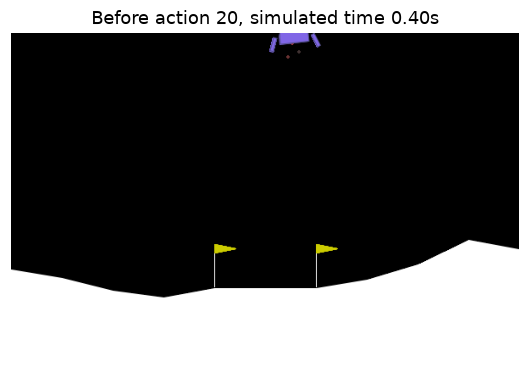

| component | s_t | s_(t+1) |
|---|---:|---:|
| `x` | +0.11165 | +0.11667 |
| `y` | +1.40086 | +1.39699 |
| `vx` | +0.49881 | +0.49362 |
| `vy` | -0.16714 | -0.17244 |
| `angle` | +0.10681 | +0.11519 |
| `angular_velocity` | +0.16935 | +0.16766 |
| `leg_0_contact` | +0.00000 | +0.00000 |
| `leg_1_contact` | +0.00000 | +0.00000 |

a_t = [0.1833445  0.04060573], decoded power = (array(0.59167224, dtype=float32), np.float32(0.0)), r_(t+1) = -0.35233
Return before transition = -0.066; after = -0.418


In [15]:
TRANSITION = 20
k = min(max(int(TRANSITION), 0), len(flight["actions"]) - 1)
fig, ax = plt.subplots(figsize=(6, 4))
ax.imshow(flight["frames"][k])
ax.set_title(f"Before action {k}, simulated time {k/FPS:.2f}s")
ax.axis("off")
plt.show()
rows = "\n".join(f"| `{name}` | {before:+.5f} | {after:+.5f} |"
                 for name, before, after in zip(NAMES, s[k], s[k+1]))
display(Markdown("| component | s_t | s_(t+1) |\n|---|---:|---:|\n" + rows))
print(f"a_t = {a[k]}, decoded power = {engine_power(a[k])}, r_(t+1) = {r[k]:+.5f}")
print(f"Return before transition = {r[:k].sum():+.3f}; after = {r[:k+1].sum():+.3f}")

## 9. Keep the demonstration, then connect it to the experiments

We save the exact configuration, measured learning curves, inference weights, each displayed trajectory, and standalone flight playback in a fresh output directory. The checkpoint supports inference, not resuming training: replay contents and optimizer state are not saved.

When you open [analysis.ipynb](analysis.ipynb), translate its metrics back to these concrete quantities: episode return describes flight performance; `Q(s,a)` predicts discounted future reward for an observation/action pair; overestimation means that prediction was too high compared with the subsequent observed return. Normalization can change how the critic learns without changing the meanings of these eight observations or two commands.

Try these small exercises:

1. In the playback, find `x > 0` and `vx < 0`. Is the craft moving toward the center?
2. Find a nonzero lateral command that leaves the side engines off.
3. At the ending, check the contact bits and both flags. Did the flight land, crash, escape, or hit the time limit?
4. Increase `TRAIN_STEPS` to 50,000 and rerun from the top. Did all three evaluation returns improve? Keep the seed fixed to compare budgets; use more independent training seeds before drawing general conclusions.

This is one small DDPG run. The project's larger experiments use different network sizes, budgets and evaluation protocols, so this notebook's scores should not be treated as reproduction of those results.

In [16]:
run_id = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ") + "-" + uuid4().hex[:8]
OUTPUT = PROJECT / "outputs" / "environment-walkthrough" / run_id
OUTPUT.mkdir(parents=True, exist_ok=False)
settings = dict(env_id="LunarLander-v3", env_settings=ENV_SETTINGS, horizon=HORIZON,
                algorithm="ddpg", hidden=[32, 32], layer_norm=False, train_seed=SEED,
                train_steps=TRAIN_STEPS, warmup=WARMUP, batch_size=BATCH_SIZE,
                replay_capacity=CAPACITY, gamma=GAMMA, tau=TAU,
                exploration_std=EXPLORATION_STD, actor_lr=LEARNING_RATE,
                critic_lr=LEARNING_RATE, updates_per_transition=1,
                eval_seeds=list(EVAL_SEEDS), eval_interval=EVAL_INTERVAL,
                flight_seed=FLIGHT_SEED, versions=VERSIONS, elapsed_seconds=elapsed,
                device="cpu", torch_threads=1)
(OUTPUT / "config.json").write_text(json.dumps(settings, indent=2))
(OUTPUT / "learning.json").write_text(json.dumps(dict(
    evaluation=[dict(step=e["step"], returns=e["returns"].tolist()) for e in evaluations],
    training_episodes=training_episodes, losses=losses), indent=2))
torch.save(dict(actor=actor.state_dict(), critic=critic.state_dict(),
                initial_actor=initial_actor.state_dict(), config=settings), OUTPUT / "inference.pt")
for i, (name, f) in enumerate(flights.items()):
    np.savez_compressed(OUTPUT / f"flight-{i}.npz", controller=name, seed=f["seed"],
                        observations=f["observations"], actions=f["actions"], rewards=f["rewards"],
                        terminated=f["terminated"], truncated=f["truncated"], outcome=f["outcome"])
(OUTPUT / "flights.html").write_text("<!doctype html><meta charset='utf-8'><title>LunarLander flights</title>"
                                     + playback_html)
print("Saved demo artifacts to", OUTPUT)
print("Standalone playback:", OUTPUT / "flights.html")

Saved demo artifacts to /Users/kat/Projects/master_ue/RL/miniproject1-DDPG/outputs/environment-walkthrough/20261006T210153Z-4c902519
Standalone playback: /Users/kat/Projects/master_ue/RL/miniproject1-DDPG/outputs/environment-walkthrough/20261006T210153Z-4c902519/flights.html
